# Детекция штрихкодов классическими методами (без нейросетей)

Задача: найти bounding box штрихкода на фото (датасет `classicData`), не используя нейросети.

Штрихкод - это частые чёрные полосы на светлом фоне, поэтому вдоль оси X яркость скачет очень резко и часто. Это хорошо ловится оператором Собеля по X: на штрихкоде отклик сильный и ровный, на фоне - слабее.

Общая схема: серый + блюр + Собель по X -> карта границ, бинаризация (Otsu) + морфологическое закрытие, чтобы полоски слиплись в один блок, дальше среди контуров-кандидатов отбрасываем мелкие/странные по форме и выбираем лучший по взвешенной сумме площади и силы границ. Веса и размер ядра закрытия - гиперпараметры, подбираю их ниже перебором по сетке на train/test.

Метрика - IOU, усреднённый по датасету, цель по заданию ~0.8.


In [ ]:
# импорты 
import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tqdm


## Настройка путей к данным

Ноутбук ожидает, что в папке `DATA_DIR` лежат:

- `annotations.tsv` - разметка;
- папка `images/` - сами фотографии.


In [ ]:
# настройки путей
DATA_DIR = Path(".")

ANNOTATIONS_PATH = DATA_DIR / "annotations.tsv"

In [ ]:
# загрузки разметки 
df = pd.read_csv(ANNOTATIONS_PATH, sep=',')

print(f"Всего размеченных изображений: {len(df)}")
df.head()

Всего размеченных изображений: 76


,filename,x_from,y_from,width,height
0,images/0b56af7e-386c-410a-8f46-74350f755d77--r...,216,474,409,308
1,images/6e042372-20ec-4a26-8340-3653cf0c681d--r...,23,849,230,125
2,images/788fb7f3-e813-4754-874f-3cc6eb19113d--r...,322,632,344,145
3,images/d05d50c0-0c19-4ca4-88ff-6f7058318a7f--r...,516,694,325,156
4,images/93cda132-8b66-476a-a112-8acf47658fee--r...,200,474,531,292


## Метрика IOU (Intersection over Union)

Каждый прямоугольник задаём кортежем `(x, y, w, h)`:
`x, y` - координаты левого верхнего угла, 
`w, h` - ширина и высота (именно в таком формате хранится разметка в `annotations.tsv`).


In [18]:
def compute_iou(box_a, box_b):
    """IOU для двух прямоугольников (x, y, w, h) - число от 0 до 1."""
    xa, ya, wa, ha = box_a
    xb, yb, wb, hb = box_b

    ax1, ay1, ax2, ay2 = xa, ya, xa + wa, ya + ha
    bx1, by1, bx2, by2 = xb, yb, xb + wb, yb + hb

    inter_x1 = max(ax1, bx1)
    inter_y1 = max(ay1, by1)
    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)

    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    area_a = wa * ha
    area_b = wb * hb
    union_area = area_a + area_b - inter_area

    if union_area <= 0:
        return 0.0

    return inter_area / union_area


## Детектор штрихкода

Пайплайн из трёх шагов, вся настройка вынесена в гиперпараметры:

- карта границ - блюр + Собель по X, полосы штрихкода дают ровный сильный отклик по всей своей площади;
- кандидаты - Otsu -> морфологическое закрытие (склеивает полоски в один блок) -> контуры -> фильтр по площади и соотношению сторон (штрихкод почти всегда шире, чем выше);
- выбор лучшего кандидата - взвешенная сумма `area_score` и `edge_score`, каждый нормирован на максимум среди кандидатов этого же фото (абсолютные пороги на разных фото ведут себя нестабильно, относительные - устойчивее).

`score = area_weight * area_score + (1 - area_weight) * edge_score`

`close_ksize` и `area_weight` подбираются по сетке в следующем разделе.


In [19]:
def _edge_map(gray):
    # карта границ: блюр + модуль производной по X (Собель)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    sobel_x = cv2.Sobel(blurred, cv2.CV_64F, dx=1, dy=0, ksize=3)
    return cv2.convertScaleAbs(sobel_x)


def _find_candidates(edge_map, close_ksize, min_area_fraction, min_aspect):
    # бинаризация + морфологическое закрытие, чтобы соседние штрихи слиплись в один плотный блок, дальше контуры этого блока - кандидаты в штрихкод
    img_h, img_w = edge_map.shape[:2]
    img_area = img_h * img_w

    _, binary = cv2.threshold(edge_map, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, close_ksize)
    closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    candidates = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        area = w * h

        if area < min_area_fraction * img_area:
            continue  # шум

        if w / max(h, 1) < min_aspect:
            continue  # слишком вытянут по вертикали, на штрихкод не похоже

        edge_strength = float(edge_map[y:y + h, x:x + w].mean())
        candidates.append({'box': (x, y, w, h), 'area': area, 'edge_strength': edge_strength})

    return candidates, binary, closed


def _pick_best(candidates, area_weight, max_aspect):
    # нормировка площади и силы границ - относительно максимума среди кандидатов этого же изображения, а не константа
    pool = [c for c in candidates if c["box"][2] / max(c["box"][3], 1) <= max_aspect]
    if not pool:
        return None

    max_area = max(c["area"] for c in pool)
    max_edge = max(c["edge_strength"] for c in pool)

    best_box, best_score = None, -1.0
    for c in pool:
        area_score = c["area"] / max_area if max_area > 0 else 0.0
        edge_score = c["edge_strength"] / max_edge if max_edge > 0 else 0.0
        score = area_weight * area_score + (1 - area_weight) * edge_score
        if score > best_score:
            best_score = score
            best_box = c["box"]

    return best_box


def detect_barcode(image_bgr, close_ksize=(15, 3), area_weight=0.4, min_area_fraction=0.0005,
                    min_aspect=0.6, max_aspect=4.0, return_debug=False):
    """
    Находит бокс штрихкода на изображении.

    close_ksize - размер ядра морфологического закрытия, 
    area_weight - вес признака площади при выборе кандидата (вес силы границ - 1 - area_weight).
    Оба подобраны перебором по сетке ниже. 
    
    return_debug=True возвращает ещё словарь с промежуточными картинками и списком кандидатов, для отладки.
    """
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    edge_map = _edge_map(gray)

    candidates, binary, closed = _find_candidates(
        edge_map, close_ksize, min_area_fraction, min_aspect
    )
    best_box = _pick_best(candidates, area_weight, max_aspect)

    if not return_debug:
        return best_box

    debug = {
        "gray": gray,
        "edge_map": edge_map,
        "binary": binary,
        "closed": closed,
        "candidates": candidates,
    }
    return best_box, debug


## Вспомогательные функции для визуализации

Рисуем ground truth бокс зелёным, предсказанный - красным.


In [20]:
def draw_box(ax, box, color, label):
    # рисует прямоугольник box=(x, y, w, h)
    if box is None:
        return
    x, y, w, h = box
    rect = plt.Rectangle((x, y), w, h, edgecolor=color, facecolor='none',
                          linewidth=2, label=label)
    ax.add_patch(rect)


def visualize_prediction(image_path, gt_box, pred_box, iou_value=None, ax=None):
    # показывает изображение с ground-truth (зелёный) и предсказанным (красный) боксами. Если ax не передан - создаёт свою фигуру

    image_bgr = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    own_fig = ax is None
    if own_fig:
        _, ax = plt.subplots(figsize=(6, 6))

    ax.imshow(image_rgb)
    draw_box(ax, gt_box, color='lime', label='Ground truth')
    draw_box(ax, pred_box, color='red', label='Prediction')

    title = Path(image_path).name
    if iou_value is not None:
        title += f"\nIOU = {iou_value:.3f}"
    ax.set_title(title, fontsize=9)
    ax.axis('off')

    if own_fig:
        ax.legend(loc='upper right', fontsize=8)
        plt.tight_layout()
        plt.show()


## Демонстрация на одном изображении

Смотрим на карту границ, бинаризацию, маску после морфологии и итоговый результат с параметрами по умолчанию - для интуиции перед тем, как переходить к подбору гиперпараметров.


Файл:         images/0b56af7e-386c-410a-8f46-74350f755d77--ru.4c7208d1-cba4-4539-967d-1c87ad0f6d2e.jpg
Ground truth: (216, 474, 409, 308)
Prediction:   (227, 479, 382, 293)
IOU:          0.888
Кандидаты (box, area, edge_strength):
  (227, 479, 382, 293)  area=111926  edge_strength=114.6
  (248, 1183, 248, 39)  area=9672  edge_strength=78.9
  (73, 1224, 289, 29)  area=8381  edge_strength=86.8
  (537, 455, 127, 50)  area=6350  edge_strength=41.7
  (75, 1186, 164, 35)  area=5740  edge_strength=92.0
  (228, 437, 113, 28)  area=3164  edge_strength=61.5
  (74, 1134, 90, 30)  area=2700  edge_strength=68.8
  (321, 378, 60, 40)  area=2400  edge_strength=40.9
  (817, 607, 29, 35)  area=1015  edge_strength=48.9
  (386, 389, 26, 34)  area=884  edge_strength=61.4


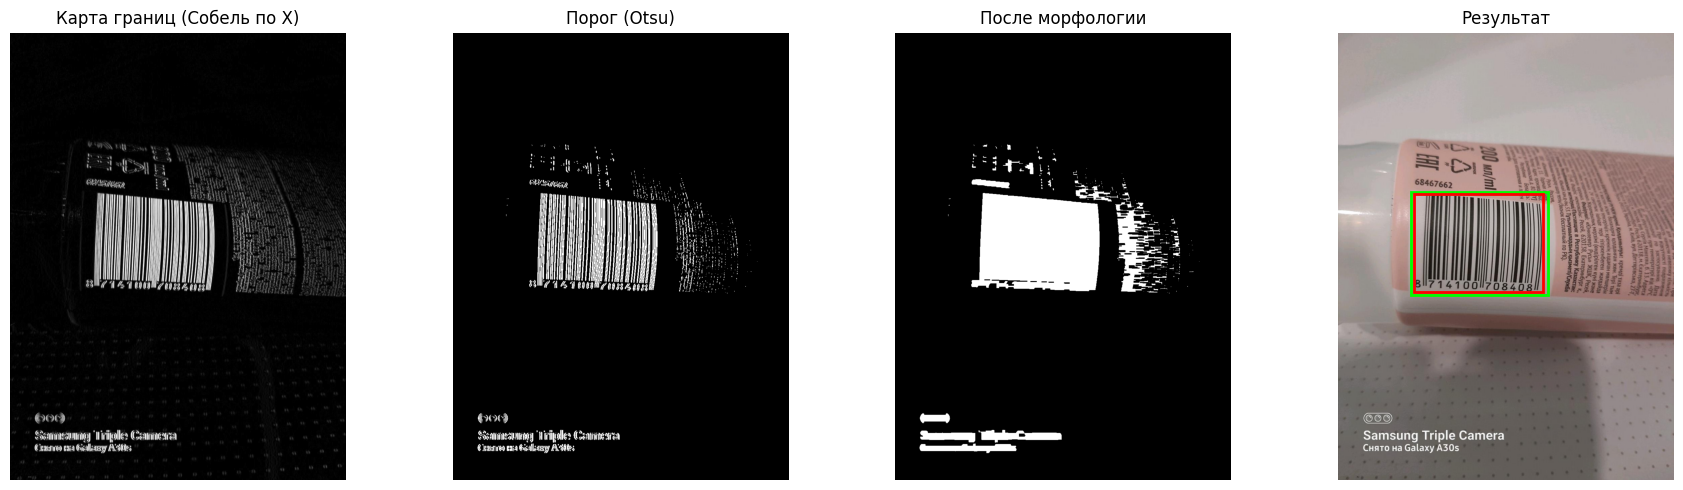

In [21]:
# берём первую строку разметки для примера - можно поменять индекс на любой
sample_row = df.iloc[0]
sample_path = DATA_DIR / sample_row['filename']
gt_box = (int(sample_row['x_from']), int(sample_row['y_from']),
          int(sample_row['width']), int(sample_row['height']))

sample_image = cv2.imread(str(sample_path))
if sample_image is None:
    raise FileNotFoundError(f"Не удалось прочитать изображение {sample_path}")

pred_box, debug = detect_barcode(sample_image, return_debug=True)
iou_value = compute_iou(gt_box, pred_box) if pred_box is not None else 0.0

print(f"Файл:         {sample_row['filename']}")
print(f"Ground truth: {gt_box}")
print(f"Prediction:   {pred_box}")
print(f"IOU:          {iou_value:.3f}")
print("Кандидаты (box, area, edge_strength):")
for c in sorted(debug['candidates'], key=lambda c: -c['area']):
    print(f"  {c['box']}  area={c['area']:.0f}  edge_strength={c['edge_strength']:.1f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(debug['edge_map'], cmap='gray')
axes[0].set_title('Карта границ (Собель по X)')
axes[1].imshow(debug['binary'], cmap='gray')
axes[1].set_title('Порог (Otsu)')
axes[2].imshow(debug['closed'], cmap='gray')
axes[2].set_title('После морфологии')
axes[3].imshow(cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB))
draw_box(axes[3], gt_box, 'lime', 'GT')
draw_box(axes[3], pred_box, 'red', 'Pred')
axes[3].set_title('Результат')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()


## Train/test и подбор гиперпараметров

Чтобы не гадать `close_ksize` и `area_weight` на глаз, делю датасет на train (перебираю по нему сетку значений и смотрю средний IOU) и test - отложенную часть, где параметры ни разу не подбирались, поэтому IOU на ней честнее показывает, чего ждать на новых фото. На 76 картинках это особенно важно: без такого разбиения легко подогнать параметры под конкретные фото, которые не обобщаются на остальные.


In [22]:
# train/test разбиение 
TEST_FRACTION = 0.25
SPLIT_SEED = 7

shuffled_df = df.sample(frac=1.0, random_state=SPLIT_SEED).reset_index(drop=True)
n_test = max(1, int(round(len(shuffled_df) * TEST_FRACTION)))

test_df = shuffled_df.iloc[:n_test].reset_index(drop=True)
train_df = shuffled_df.iloc[n_test:].reset_index(drop=True)

print(f"Train: {len(train_df)} изображений")
print(f"Test:  {len(test_df)} изображений")


Train: 57 изображений
Test:  19 изображений


In [23]:
def mean_iou_for_params(rows_df, close_ksize, area_weight):
    # средний IOU алгоритма с заданными гиперпараметрами на наборе строк разметки.
    ious = []
    for _, row in rows_df.iterrows():
        image = cv2.imread(str(DATA_DIR / row['filename']))
        if image is None:
            continue
        gt_box = (int(row['x_from']), int(row['y_from']), int(row['width']), int(row['height']))
        pred_box = detect_barcode(image, close_ksize=close_ksize, area_weight=area_weight)
        ious.append(compute_iou(gt_box, pred_box) if pred_box is not None else 0.0)
    return float(np.mean(ious)) if ious else 0.0


# сетка значений для перебора
CLOSE_KSIZE_GRID = [(9, 3), (13, 3), (15, 3), (17, 3), (17, 5), (21, 5), (25, 5), (31, 7)]
AREA_WEIGHT_GRID = [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]

# все комбинации параметров одним списком
param_combos = [(ksize, aw) for ksize in CLOSE_KSIZE_GRID for aw in AREA_WEIGHT_GRID]

grid_rows = []
for ksize, aw in tqdm(param_combos, desc="Перебор гиперпараметров"):
    train_iou = mean_iou_for_params(train_df, ksize, aw)
    grid_rows.append({"close_ksize": ksize, "area_weight": aw, "train_mean_iou": train_iou})

grid_df = pd.DataFrame(grid_rows).sort_values("train_mean_iou", ascending=False).reset_index(drop=True)
grid_df.head(10)


TypeError: 'module' object is not callable

In [ ]:
BEST_CLOSE_KSIZE = grid_df.iloc[0]["close_ksize"]
BEST_AREA_WEIGHT = grid_df.iloc[0]["area_weight"]

print(f"Лучшие параметры по train: close_ksize={BEST_CLOSE_KSIZE}, area_weight={BEST_AREA_WEIGHT}")
print(f"Train mean IOU:  {grid_df.iloc[0]['train_mean_iou']:.4f}")

test_mean_iou = mean_iou_for_params(test_df, BEST_CLOSE_KSIZE, BEST_AREA_WEIGHT)
print(f"Test mean IOU:   {test_mean_iou:.4f}  <- честная оценка на отложенных данных")


Лучшие параметры по train: close_ksize=(15, 3), area_weight=0.3
Train mean IOU:  0.8504
Test mean IOU:   0.8068  <- честная оценка на отложенных данных


## Финальный прогон по всему датасету

С пподобранными параметрами прогоняем алгоритм на всех изображениях - цифра `test_mean_iou` будет чуть выше (часть изображений участвовала в подборе параметров), но это будет буквально "средний IOU по датасету" как указано в условии.


In [ ]:
results = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Детекция штрихкодов"):
    image_path = DATA_DIR / row['filename']
    gt_box = (int(row['x_from']), int(row['y_from']),
              int(row['width']), int(row['height']))

    image = cv2.imread(str(image_path))
    if image is None:
        print(f"Не удалось прочитать {image_path}, пропускаем")
        continue

    pred_box = detect_barcode(image, close_ksize=BEST_CLOSE_KSIZE, area_weight=BEST_AREA_WEIGHT)
    iou_value = compute_iou(gt_box, pred_box) if pred_box is not None else 0.0

    results.append({
        "filename": row['filename'],
        "gt_box": gt_box,
        "pred_box": pred_box,
        "iou": iou_value,
    })

results_df = pd.DataFrame(results)

print(f"Обработано изображений:        {len(results_df)}")
print(f"Средний IOU (mean):            {results_df['iou'].mean():.4f}")
print(f"Медианный IOU (median):        {results_df['iou'].median():.4f}")
print(f"Доля изображений с IOU >= 0.5: {(results_df['iou'] >= 0.5).mean():.2%}")
print(f"Доля изображений с IOU >= 0.8: {(results_df['iou'] >= 0.8).mean():.2%}")


Детекция штрихкодов: 100%|██████████| 76/76 [00:02<00:00, 32.44it/s]

Обработано изображений:        76
Средний IOU (mean):            0.8395
Медианный IOU (median):        0.9037
Доля изображений с IOU >= 0.5: 93.42%
Доля изображений с IOU >= 0.8: 82.89%


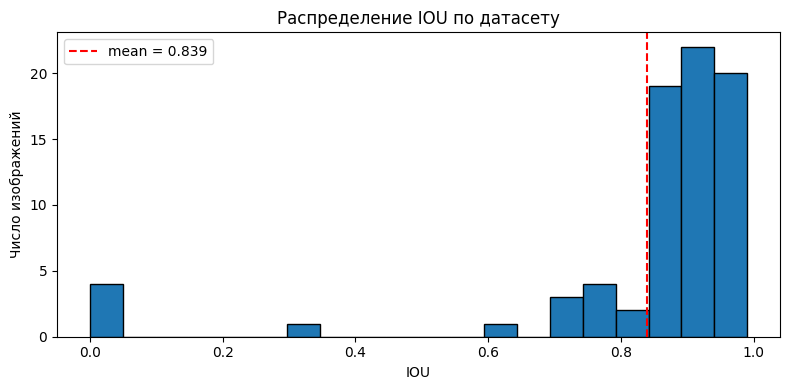

In [ ]:
# гистограмма распределения IOU по датасету
plt.figure(figsize=(8, 4))
plt.hist(results_df['iou'], bins=20, edgecolor='black')
plt.axvline(results_df['iou'].mean(), color='red', linestyle='--',
            label=f"mean = {results_df['iou'].mean():.3f}")
plt.xlabel('IOU')
plt.ylabel('Число изображений')
plt.title('Распределение IOU по датасету')
plt.legend()
plt.tight_layout()
plt.show()


## Лучшие и худшие предсказания


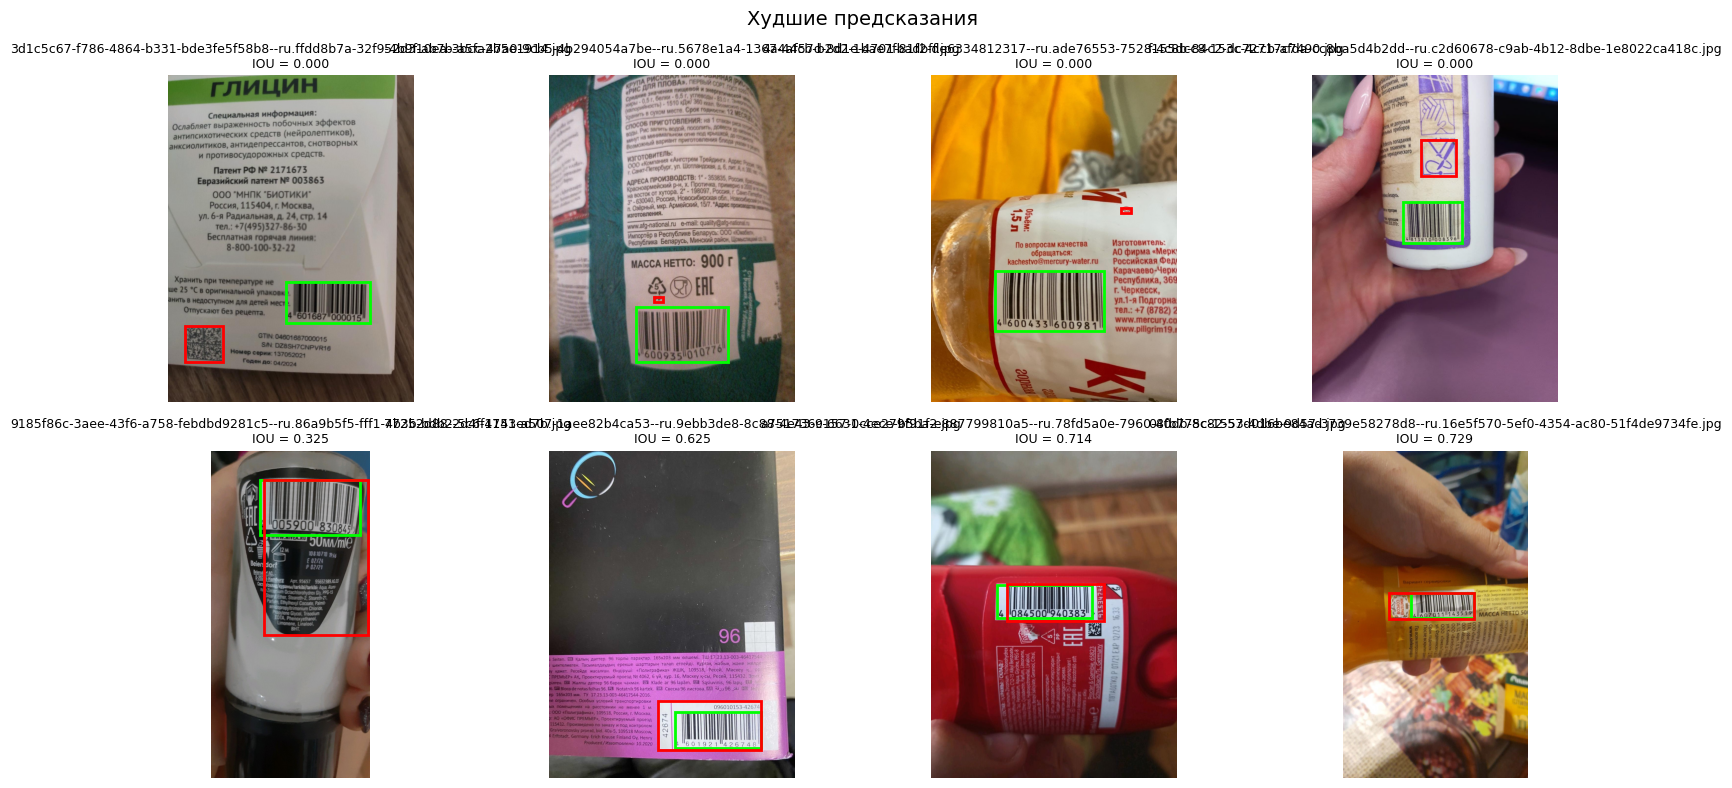

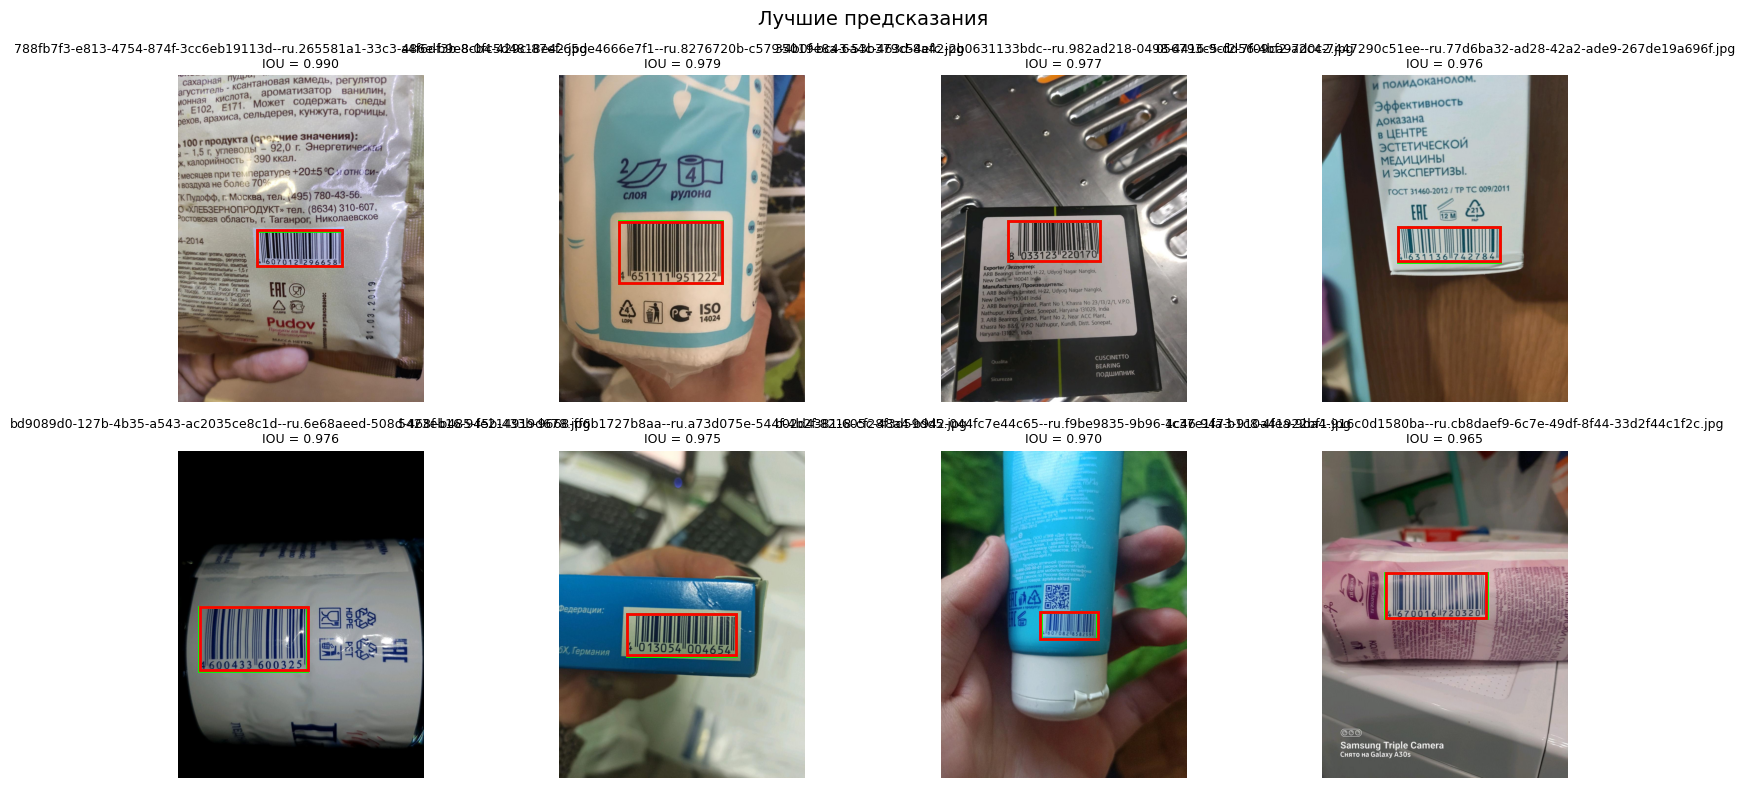

In [ ]:
def show_examples(rows, n_cols=4, title=""):
    # показывает сетку изображений с GT и предсказанными боксами.
    n = len(rows)
    n_cols = min(n_cols, max(n, 1))
    n_rows = (n + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, row) in zip(axes, rows.iterrows()):
        image_path = DATA_DIR / row['filename']
        visualize_prediction(image_path, row['gt_box'], row['pred_box'], row['iou'], ax=ax)

    for ax in axes[len(rows):]:
        ax.axis('off')

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


worst = results_df.sort_values('iou').head(8)
show_examples(worst, title="Худшие предсказания")

best = results_df.sort_values('iou', ascending=False).head(8)
show_examples(best, title="Лучшие предсказания")


## Сохранение результатов

Сохраняем таблицу с IOU по каждому изображению.


In [ ]:
results_df.to_csv("iou_results.csv", index=False)
grid_df.to_csv("grid_search_results.csv", index=False)
print("Результаты сохранены в iou_results.csv и grid_search_results.csv")


Результаты сохранены в iou_results.csv и grid_search_results.csv
